# Individual-Differences Data Analysis

Standalone quality audit and descriptive analysis of the MECO-L2 participant measures. This notebook intentionally does not merge comprehension, fixation, or reading-rate data.

## Scope

The goal is to determine whether the individual-difference data require preprocessing, identify redundant measures, and assess whether standardized composites are defensible for a future integrated analysis.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd()
while not (ROOT / 'pyproject.toml').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from analysis.individual_differences.io import MEASURES, load_data, missingness_summary, language_summary
from analysis.individual_differences.features import add_composites, correlation_table, standardize_within_wave
from analysis.individual_differences.plots import plot_correlations, plot_distributions, plot_language_profiles, plot_missingness

OUTPUT = ROOT / 'analysis' / 'individual_differences' / 'output' / 'notebook'
PLOTS = OUTPUT / 'plots'
OUTPUT.mkdir(parents=True, exist_ok=True)
PLOTS.mkdir(parents=True, exist_ok=True)

## Dataset Overview

In [2]:
data = load_data('both')
print(f'Rows: {len(data):,}')
print(f'Participants: {data.participant_id.nunique():,}')
print(f'Measures: {len(MEASURES)}')
display(data.groupby(['wave', 'lang'], observed=True).size().reset_index(name='participants'))
display(data[MEASURES].describe().T)

Rows: 1,204
Participants: 1,204
Measures: 8


,wave,lang,participants
0,1,du,47
1,1,ee,58
2,1,en,45
3,1,fi,51
4,1,ge,45
5,1,gr,48
6,1,he,45
7,1,it,51
8,1,no,40
9,1,ru,47


,count,mean,std,min,25%,50%,75%,max
spelling,1187.0,35.037068,4.853883,19.00,32.0,35.00,38.00,76.0
motiv,1156.0,3.605709,0.360234,2.20,3.4,3.60,3.90,4.4
lextale,1100.0,76.662536,12.456033,41.25,67.5,76.25,86.25,100.0
TOWRE_word,1098.0,80.266849,14.837031,25.00,73.0,82.00,90.00,104.0
TOWRE_nonword,1098.0,49.782332,10.613324,0.00,44.0,52.00,58.00,69.0
vocab,1167.0,46.681234,23.616421,3.00,24.0,46.00,68.00,88.0
vocab.t2.5,1167.0,30.497001,9.799173,3.00,24.0,35.00,38.00,40.0
cft20,1081.0,9.013876,1.964686,1.00,8.0,9.00,10.00,15.0


## Missingness and Quality

,wave,measure,n,missing,missing_proportion
0,1,spelling,543,4,0.007366
1,1,motiv,543,3,0.005525
2,1,lextale,543,6,0.011050
3,1,TOWRE_word,543,3,0.005525
4,1,TOWRE_nonword,543,3,0.005525
5,1,vocab,543,7,0.012891
6,1,vocab.t2.5,543,7,0.012891
7,1,cft20,543,22,0.040516
8,2,spelling,661,13,0.019667
9,2,motiv,661,45,0.068079


,size,complete_cases
wave,,
1,543,507
2,661,504


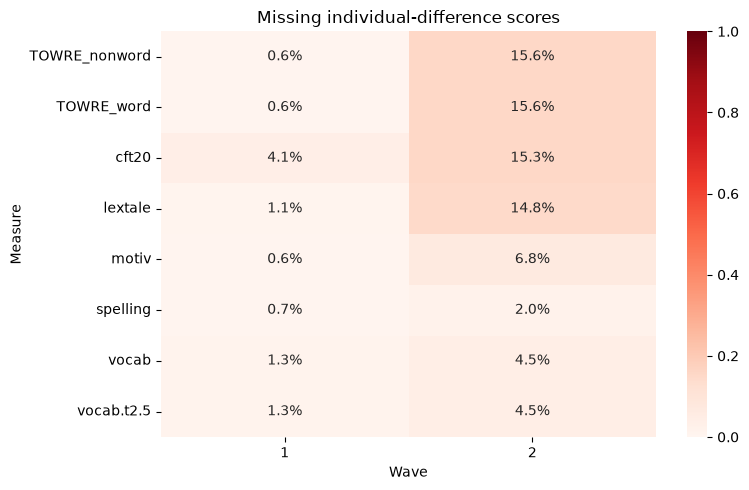

In [3]:
display(missingness_summary(data))
display(data.groupby('wave', observed=True)['all_measures_complete'].agg(['size', 'sum']).rename(columns={'sum': 'complete_cases'}))
for fig in [plot_missingness(data, PLOTS)]:
    display(fig)
    plt.close(fig)

In [4]:
quality_columns = ['duplicate_rows', 'id_valid', 'lang_id_consistent', 'numeric_conversion_issue']
available_quality = [column for column in quality_columns if column in data.columns]
display(data[available_quality].agg(['sum', 'mean']).T)
display(data[[column for column in data.columns if column.endswith('_out_of_plausible_range')]].sum())

,sum,mean
id_valid,1204.0,1.0
lang_id_consistent,1204.0,1.0
numeric_conversion_issue,0.0,0.0


spelling_out_of_plausible_range         0
motiv_out_of_plausible_range            0
lextale_out_of_plausible_range          0
TOWRE_word_out_of_plausible_range       0
TOWRE_nonword_out_of_plausible_range    0
vocab_out_of_plausible_range            0
vocab.t2.5_out_of_plausible_range       0
cft20_out_of_plausible_range            0
dtype: int64

## Score Distributions

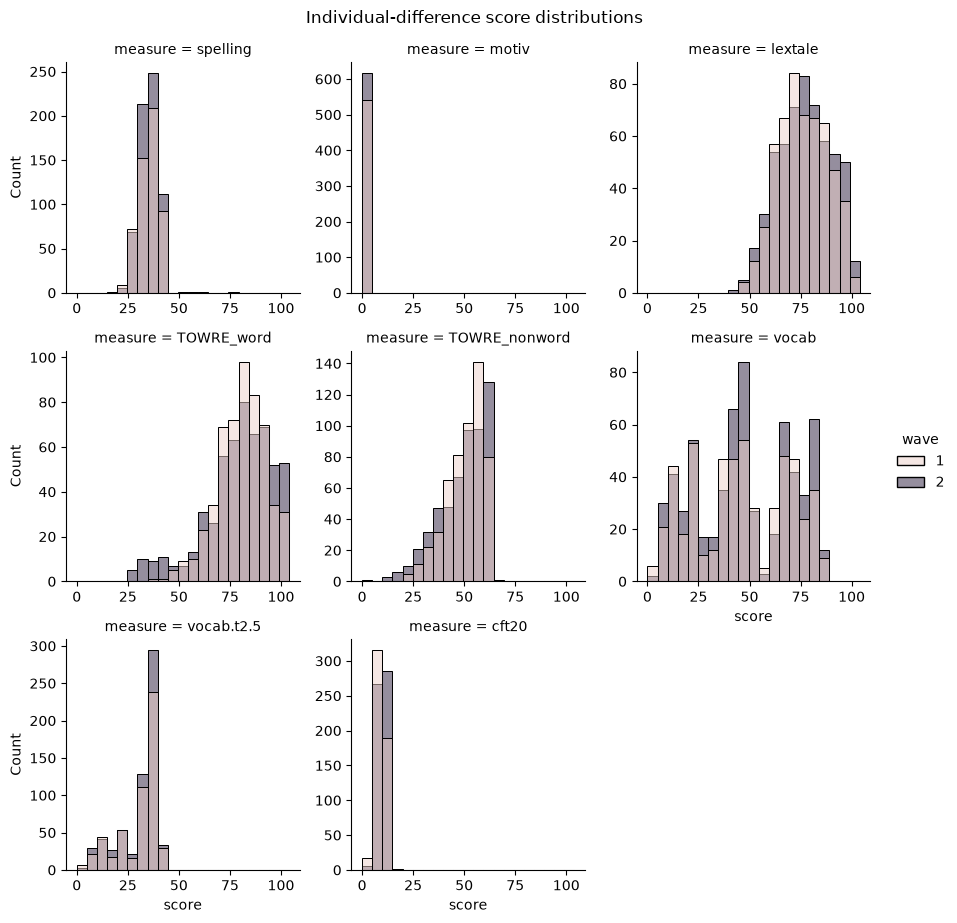

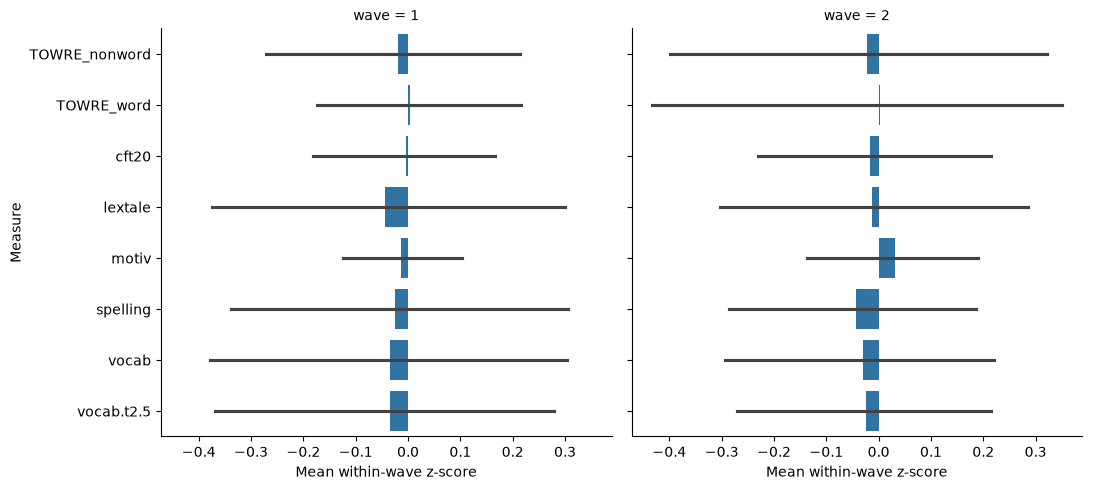

In [5]:
fig = plot_distributions(data, PLOTS)
display(fig)
plt.close(fig)
fig = plot_language_profiles(data, PLOTS)
display(fig)
plt.close(fig)

## Measure Redundancy

,measure,spelling,motiv,lextale,TOWRE_word,TOWRE_nonword,vocab,vocab.t2.5,cft20,wave
0,spelling,1.000000,0.161969,0.579884,0.192880,0.230744,0.436915,0.400484,0.005745,1
1,motiv,0.161969,1.000000,0.196787,0.025406,0.046427,0.189740,0.165912,0.017156,1
2,lextale,0.579884,0.196787,1.000000,0.237468,0.287520,0.719199,0.630248,0.075076,1
3,TOWRE_word,0.192880,0.025406,0.237468,1.000000,0.575179,0.213153,0.209909,0.056497,1
4,TOWRE_nonword,0.230744,0.046427,0.287520,0.575179,1.000000,0.258020,0.252791,0.047295,1
5,vocab,0.436915,0.189740,0.719199,0.213153,0.258020,1.000000,0.874640,0.078948,1
6,vocab.t2.5,0.400484,0.165912,0.630248,0.209909,0.252791,0.874640,1.000000,0.115692,1
7,cft20,0.005745,0.017156,0.075076,0.056497,0.047295,0.078948,0.115692,1.000000,1
8,spelling,1.000000,0.197834,0.502762,0.274698,0.416021,0.414787,0.369064,0.035675,2
9,motiv,0.197834,1.000000,0.180303,0.006949,0.029186,0.204786,0.207533,0.059678,2


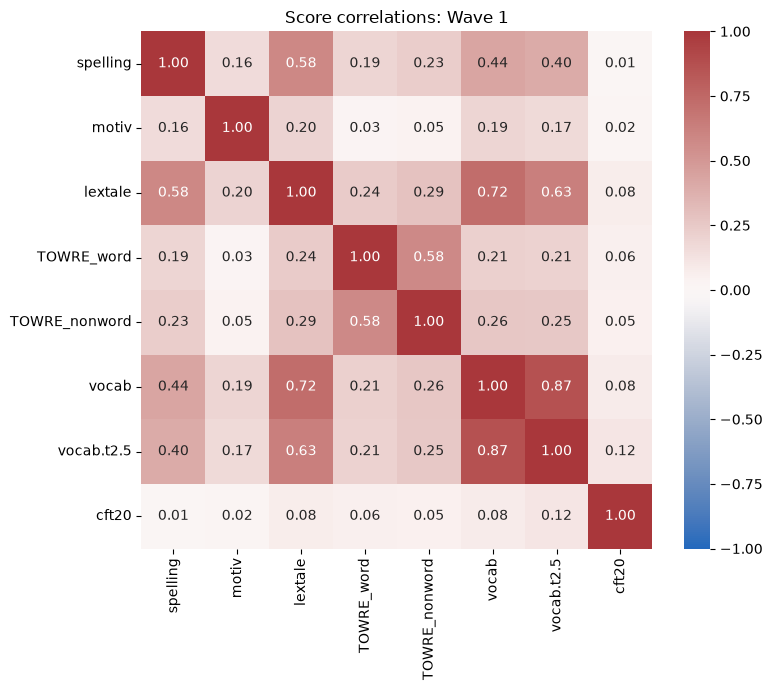

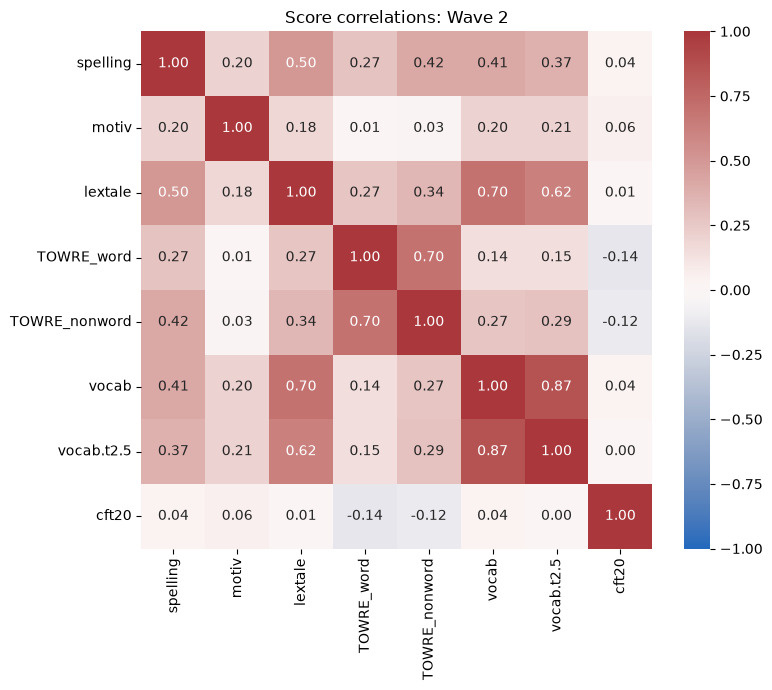

In [6]:
display(correlation_table(data))
for fig in plot_correlations(data, PLOTS):
    display(fig)
    plt.close(fig)

## Standardized Scores and Composites

Scores are standardized within wave. The language-skill composite is the mean of LexTALE, capped vocabulary, and the two TOWRE measures. Raw scores are not summed because their scales differ.

In [7]:
standardized = add_composites(standardize_within_wave(data))
display(standardized.groupby('wave', observed=True)[['language_skill_composite', 'cognitive_skill', 'motivation_standardized', 'spelling_standardized']].agg(['count', 'mean', 'std']))
standardized.to_csv(OUTPUT / 'individual_differences_standardized.csv', index=False)

language_skill_composite                     cognitive_skill  \
                        count      mean       std           count   
wave                                                                
1                         527  0.000010  0.726597             521   
2                         504  0.024955  0.718024             560   

                             motivation_standardized                          \
              mean       std                   count          mean       std   
wave                                                                           
1     5.977304e-17  1.000961                     540  8.546661e-16  1.000927   
2     1.641544e-16  1.000894                     616 -5.734951e-16  1.000813   

     spelling_standardized                          
                     count          mean       std  
wave                                                
1                      539 -5.898768e-16  1.000929  
2                      648 -2.709595e-16  1.000772

## Conclusion

Use this audit to decide which measures are sufficiently complete and non-redundant for a future integrated analysis. Do not impute or remove flagged values without checking the original test definitions.